# Week 12 lecture demo: checking AI output
**No live prompting, no network.** Every AI response here was generated ahead of time (Claude, fresh chats, Nov 4 2026) and saved in this folder. These cells *check* them.

Jump to: [1. Number from nowhere](#1.-Number-from-nowhere-(5-fresh-chats)) · [2. Citations](#2.-Citations) · [3. A function that doesn't exist](#3.-A-function-that-doesn't-exist) · [4. An agent in a project](#4.-An-agent-working-in-a-project)

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
pd.set_option("display.width", 180, "display.max_colwidth", 80)

## 1. Number from nowhere (5 fresh chats)
Prompt (`prompt_q4.txt`): *median overall survival, in months, for stage IV patients in TCGA LUAD. Give me one number.* No data attached. Five separate chats. The file's real answer comes from Week 11's ground-truth code.

In [2]:
df = pd.read_csv("data_clinical_patient.txt", sep="\t", comment="#").dropna(subset=["OS_MONTHS", "OS_STATUS"])
df["event"] = df.OS_STATUS.str.startswith("1").astype(int)
g = df[df.AJCC_PATHOLOGIC_TUMOR_STAGE == "STAGE IV"]
truth = KaplanMeierFitter().fit(g.OS_MONTHS, g.event).median_survival_time_
print(f"Stage IV: n={len(g)}, Kaplan-Meier median = {truth:.1f} months")

Stage IV: n=27, Kaplan-Meier median = 27.2 months


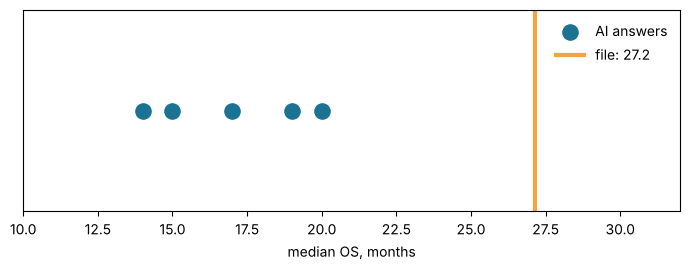

Every response also said it could not verify the number. Every response gave one anyway.


In [3]:
answers = {"run 1": 20, "run 2": 17, "run 3": 19, "run 4": 14, "run 5": 15}   # from response_q4_run*.md
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.scatter(list(answers.values()), [0]*5, s=120, color="#1C7293", label="AI answers", zorder=3)
ax.axvline(truth, color="#F2A541", lw=3, label=f"file: {truth:.1f}")
ax.set_xlim(10, 32); ax.set_yticks([]); ax.set_xlabel("median OS, months"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("Every response also said it could not verify the number. Every response gave one anyway.")

## 2. Citations
Prompt (`prompt_q2.txt`): five peer-reviewed references with DOIs. The response said up front to verify them. Each DOI was looked up in Crossref on Nov 4 2026 (not re-run here).

In [4]:
pd.read_csv("citation_check.tsv", sep="\t")[["n", "cited_authors", "cited_year", "crossref_journal", "result"]]

,n,cited_authors,cited_year,crossref_journal,result
0,1,"Kaplan, Meier",1958,Journal of the American Statistical Association,"exists, matches"
1,2,"Schemper, Smith",1996,Controlled Clinical Trials,"exists, matches"
2,3,"Clark, Bradburn, Love, Altman",2003,British Journal of Cancer,"exists, matches"
3,4,"Liu, Lichtenberg, Hoadley et al.",2018,Cell,"exists, matches"
4,5,"Rich, Neely, Paniello, Voelker, Nussenbaum, Wang",2010,Otolaryngology-Head and Neck Surgery,"exists, matches"


All five exist and match. Checking took a few minutes. What this does **not** check: whether each paper actually says what the AI claimed it says.

## 3. A function that doesn't exist
Prompt (`prompt_q3.txt`) assumed a lifelines function with a `by=` argument. Existence check, one line each:

In [5]:
import lifelines.utils as u
print([n for n in dir(u) if "restricted" in n.lower()])
print("restricted_mean_survival_time_by exists?", hasattr(u, "restricted_mean_survival_time_by"))

['restricted_mean_survival_time']
restricted_mean_survival_time_by exists? False


The response pushed back on the premise and offered a loop instead. Run its code (on the TCGA data: `df` = clinical table, `group` = sex, 24-month RMST):

In [6]:
%run q3_check.py

RMST Female=21.60, Male=20.51, diff=1.09, p=0.8992


It runs. (Cross-check against another tool before reporting that p-value.)

## 4. An agent working in a project
Task (`prompt_agent.txt`): add `flag_out_of_range(df)` with sex-specific reference ranges, add tests, make them pass. An agent with file and shell access did the work in a toy repo, `agent_run/`. Its full diff is `agent_run_diff.patch`.

In [7]:
import subprocess
r = subprocess.run(["python", "-m", "pytest", "-q", "--color=no"], cwd="agent_run", capture_output=True, text=True)
print(r.stdout[-300:])

.......                                                                  [100%]
7 passed in 0.50s



In [8]:
# independent check of its claim "15 of 36 rows flagged"
labs = pd.read_csv("agent_run/data/labs.tsv", sep="\t")
def bad(r):
    v = r.value
    if r.test == "glucose":
        v = v * 18.016 if r.unit == "mmol/L" else v
        return not (70 <= v <= 99)
    lo, hi = {"creatinine": {"F": (0.59, 1.04), "M": (0.74, 1.35)}, "hemoglobin": {"F": (12.0, 15.5), "M": (13.5, 17.5)}}[r.test][r.sex]
    return not (lo <= v <= hi)
print(labs.apply(bad, axis=1).sum(), "of", len(labs), "flagged")

15 of 36 flagged


**What the tests cannot tell you**
- The ranges are the agent's own picks (it said so). **Source: none.** Glucose is assumed *fasting* and the same for both sexes; the data does not say if samples were fasting.
- The tests use boundary values taken from those same ranges, so they pass by construction. A wrong range would pass too.
- `test_does_not_mutate_input_and_keeps_rows` reads `data/labs.tsv` by relative path, so it only works when run from the repo root.

What it did well: it flagged its own assumptions, converted mmol/L before comparing, and chose `<NA>` over a guess for unknown rows.